# Notebook 8: Model 1 Verification — Leakage Detection Suite
## Three-Test Protocol for Publication-Grade Validation

**Tests:**
- **Test A:** Random label test — AUC should drop to ~0.50 if model is genuine
- **Test B:** Proper pipeline split — VAE trained ONLY on train set, test set transformed only
- **Test C:** Permutation test (1000 shuffles) — p < 0.001 required

> *"Without these three tests, a high AUC on a self-supervised label is scientifically meaningless."*


## 0. Setup & Load Data

In [1]:
import os, warnings, random, time
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import (
    StratifiedKFold, StratifiedShuffleSplit,
    cross_val_score, permutation_test_score
)
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score,
    roc_curve, classification_report
)
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from scipy import stats

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

BASE_DIR = r'D:\CDAC_Project\PAN-DATASET'   # ← CHANGE TO YOUR DATASET ROOT
OUT_DIR  = os.path.join(BASE_DIR, 'model_outputs')
PREP_DIR = os.path.join(BASE_DIR, 'preprocessed')
EVAL_DIR = os.path.join(OUT_DIR,  'evaluation_report')
VERIF_DIR= os.path.join(OUT_DIR,  'verification_tests')
os.makedirs(VERIF_DIR, exist_ok=True)
print(f'Device : {DEVICE}')
print(f'Output : {VERIF_DIR}')


Device : cpu
Output : D:\CDAC_Project\PAN-DATASET\model_outputs\verification_tests


In [2]:
# Load raw multi-omics inputs (BEFORE VAE — we need to retrain VAE from scratch)
tcga_rna  = pd.read_csv(os.path.join(PREP_DIR,'tcga_rna_preprocessed.csv'),   index_col=0)
mut_raw   = pd.read_csv(os.path.join(PREP_DIR,'mutation_matrix_preprocessed.csv'), index_col=0)

# Align mutation to RNA patients
common_pts = tcga_rna.index
mut_aligned = mut_raw.reindex(common_pts).fillna(0)

# Build raw joint matrix (RNA + mutation) — same as Notebook 3
rna_arr  = tcga_rna.values.astype(np.float32)
mut_arr  = mut_aligned.values.astype(np.float32)
X_raw    = np.concatenate([rna_arr, mut_arr], axis=1)
X_raw    = np.nan_to_num(X_raw, nan=0.0)
N_PATIENTS  = len(X_raw)
INPUT_DIM   = X_raw.shape[1]
LATENT_DIM  = 64

print(f'Patients  : {N_PATIENTS}')
print(f'Input dim : {INPUT_DIM}')
print(f'Latent dim: {LATENT_DIM}')

# Also load the ALREADY-TRAINED fused features (for comparison)
X_fused_old = np.load(os.path.join(OUT_DIR,'X_fused.npy'))
print(f'Old fused features shape: {X_fused_old.shape}')


Patients  : 183
Input dim : 506
Latent dim: 64
Old fused features shape: (183, 128)


## 0.1 VAE Definition (reused across all tests)

In [3]:
class VAE(nn.Module):
    def __init__(self, input_dim, hidden_dim=256, latent_dim=64):
        super().__init__()
        self.enc_fc1   = nn.Linear(input_dim, hidden_dim)
        self.enc_fc2   = nn.Linear(hidden_dim, hidden_dim//2)
        self.enc_bn1   = nn.BatchNorm1d(hidden_dim)
        self.enc_bn2   = nn.BatchNorm1d(hidden_dim//2)
        self.fc_mu     = nn.Linear(hidden_dim//2, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim//2, latent_dim)
        self.dec_fc1   = nn.Linear(latent_dim, hidden_dim//2)
        self.dec_fc2   = nn.Linear(hidden_dim//2, hidden_dim)
        self.dec_out   = nn.Linear(hidden_dim, input_dim)
        self.dec_bn1   = nn.BatchNorm1d(hidden_dim//2)
        self.dec_bn2   = nn.BatchNorm1d(hidden_dim)
        self.dropout   = nn.Dropout(0.2)

    def encode(self, x):
        h = F.relu(self.enc_bn1(self.enc_fc1(x)))
        h = self.dropout(h)
        h = F.relu(self.enc_bn2(self.enc_fc2(h)))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        if self.training:
            return mu + torch.randn_like(mu) * torch.exp(0.5*logvar)
        return mu

    def decode(self, z):
        h = F.relu(self.dec_bn1(self.dec_fc1(z)))
        h = F.relu(self.dec_bn2(self.dec_fc2(h)))
        return self.dec_out(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

def vae_loss_fn(recon, x, mu, logvar, beta=1.0):
    rl  = F.mse_loss(recon, x, reduction='mean')
    kld = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    return rl + beta*kld

def train_vae(X_train_np, input_dim, latent_dim=64, epochs=80, lr=1e-3, batch=32, seed=42):
    """Train a fresh VAE on X_train_np and return the model."""
    torch.manual_seed(seed)
    model = VAE(input_dim, 256, latent_dim).to(DEVICE)
    opt   = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    ds    = TensorDataset(torch.FloatTensor(X_train_np))
    ldr   = DataLoader(ds, batch_size=batch, shuffle=True, drop_last=False)
    for epoch in range(1, epochs+1):
        model.train()
        for (bx,) in ldr:
            bx = bx.to(DEVICE)
            opt.zero_grad()
            recon, mu, logvar = model(bx)
            loss = vae_loss_fn(recon, bx, mu, logvar)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        sched.step()
    return model

def encode_vae(model, X_np):
    """Encode data through trained VAE and return latent mu."""
    model.eval()
    with torch.no_grad():
        mu, _ = model.encode(torch.FloatTensor(X_np).to(DEVICE))
    return mu.cpu().numpy()

def make_pc1_labels(Z, threshold_pct=(40, 60)):
    """Build binary labels from PC1 of latent space.
       Bottom threshold_pct[0]% = 0, Top (100-threshold_pct[1])% = 1.
       Returns X_selected, y_selected (indices removed middle).
    """
    pca = PCA(n_components=1, random_state=SEED)
    pc1 = pca.fit_transform(Z).ravel()
    lo  = np.percentile(pc1, threshold_pct[0])
    hi  = np.percentile(pc1, threshold_pct[1])
    low_mask  = pc1 <= lo
    high_mask = pc1 >= hi
    sel_mask  = low_mask | high_mask
    y = high_mask[sel_mask].astype(int)
    return np.where(sel_mask)[0], y   # original indices, labels

def build_xgb(scale_pos=1.0, seed=SEED):
    return XGBClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.05,
        subsample=0.7, colsample_bytree=0.7, min_child_weight=5,
        gamma=0.3, reg_alpha=0.5, reg_lambda=2.0,
        scale_pos_weight=scale_pos,
        use_label_encoder=False, eval_metric='logloss',
        random_state=seed, n_jobs=-1
    )

print('VAE and helper functions defined.')


VAE and helper functions defined.


---
## TEST A: Random Label Test
**What it does:** Replaces all real labels with completely random 0/1 labels.

**Expected result:** AUC ≈ 0.50 (random).

**What it proves:**
- If AUC stays high with random labels → the model is fitting noise / data structure, not biology → **leakage confirmed**
- If AUC drops to ~0.50 → the model requires the real labels to perform → **model is genuine**


In [4]:
print('='*60)
print('TEST A: RANDOM LABEL TEST')
print('='*60)

# Use the existing fused features (already computed in Notebook 4)
# Build original PC1 labels on full data
Z_old = X_fused_old   # already encoded latent features
pca_full = PCA(n_components=1, random_state=SEED)
pc1_full = pca_full.fit_transform(Z_old).ravel()
lo_full  = np.percentile(pc1_full, 40)
hi_full  = np.percentile(pc1_full, 60)
low_m    = pc1_full <= lo_full
high_m   = pc1_full >= hi_full
sel_m    = low_m | high_m
y_real   = high_m[sel_m].astype(int)
X_sel    = Z_old[sel_m]
print(f'Original dataset: {X_sel.shape[0]} patients, {y_real.sum()} class-1')

skf      = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
real_aucs = []
rand_aucs_A = []
N_RAND_A  = 100   # number of random label iterations

# Real labels AUC
for tr, te in skf.split(X_sel, y_real):
    xb = build_xgb(scale_pos=(y_real[tr]==0).sum()/max((y_real[tr]==1).sum(),1))
    xb.fit(X_sel[tr], y_real[tr])
    prob = xb.predict_proba(X_sel[te])[:,1]
    if len(np.unique(y_real[te])) == 2:
        real_aucs.append(roc_auc_score(y_real[te], prob))

real_auc_mean = np.mean(real_aucs)
print(f'AUC with REAL labels     : {real_auc_mean:.4f} +/- {np.std(real_aucs):.4f}')

# Random labels AUC — repeated 100 times
print(f'Running {N_RAND_A} random label iterations...')
for trial in range(N_RAND_A):
    y_rand = np.random.RandomState(trial).permutation(y_real)
    trial_aucs = []
    for tr, te in skf.split(X_sel, y_rand):
        if len(np.unique(y_rand[te])) < 2:
            continue
        xb = build_xgb(seed=SEED+trial)
        xb.fit(X_sel[tr], y_rand[tr])
        prob = xb.predict_proba(X_sel[te])[:,1]
        trial_aucs.append(roc_auc_score(y_rand[te], prob))
    if trial_aucs:
        rand_aucs_A.append(np.mean(trial_aucs))

rand_mean_A = np.mean(rand_aucs_A)
rand_std_A  = np.std(rand_aucs_A)

# Statistical test: is real AUC significantly above random?
t_stat, p_val_A = stats.ttest_1samp(rand_aucs_A, real_auc_mean)
p_val_A = 1 - stats.ttest_1samp(rand_aucs_A, real_auc_mean).pvalue / 2

print(f'AUC with RANDOM labels   : {rand_mean_A:.4f} +/- {rand_std_A:.4f}')
print(f'Difference               : {real_auc_mean - rand_mean_A:+.4f}')
print()

if rand_mean_A > 0.65:
    verdict_A = 'LEAKAGE DETECTED — Random labels also give high AUC'
    color_A   = 'red'
    print(f'VERDICT: {verdict_A}')
    print('  The model learns from data structure alone, not real labels.')
    print('  Proceed to Test B to quantify the leakage.')
elif real_auc_mean - rand_mean_A > 0.10:
    verdict_A = 'GENUINE SIGNAL — Real labels significantly outperform random'
    color_A   = 'green'
    print(f'VERDICT: {verdict_A}')
else:
    verdict_A = 'WEAK SIGNAL — Small difference between real and random'
    color_A   = 'orange'
    print(f'VERDICT: {verdict_A}')

print(f'Random label AUC mean: {rand_mean_A:.4f} (expected ~0.50 if no leakage)')


TEST A: RANDOM LABEL TEST
Original dataset: 146 patients, 73 class-1
AUC with REAL labels     : 0.9990 +/- 0.0019
Running 100 random label iterations...
AUC with RANDOM labels   : 0.4958 +/- 0.0556
Difference               : +0.5033

VERDICT: GENUINE SIGNAL — Real labels significantly outperform random
Random label AUC mean: 0.4958 (expected ~0.50 if no leakage)


---
## TEST B: Proper Pipeline Split (Correct Procedure)
**The problem with the original approach:**
```
All patients → Train VAE → PC1 labels → Train/Test split → XGBoost
```
The VAE saw ALL patients (including test patients) when generating PC1 labels.
Test patients' information leaked into the label generation step.

**The correct procedure:**
```
Split patients FIRST (70% train, 30% test)
    ↓
Train VAE on TRAIN SET ONLY
    ↓
Generate PC1 labels from TRAIN SET ONLY
    ↓
Transform TEST SET through trained VAE (no retraining)
    ↓
Train XGBoost on train set → Evaluate on test set
```
**If AUC drops significantly → original result was optimistic.**


In [5]:
print('='*60)
print('TEST B: PROPER PIPELINE SPLIT')
print('='*60)
print('This is the most important test. It takes ~5-10 minutes.')
print()

N_REPEATS_B = 10   # repeat the split 10 times for stable estimate
test_aucs_B = []
test_accs_B = []

for repeat in range(N_REPEATS_B):
    print(f'  Repeat {repeat+1}/{N_REPEATS_B}...', end=' ', flush=True)
    t0 = time.time()

    # ── Step 1: Split patients FIRST ────────────────────────────────────
    sss = StratifiedShuffleSplit(n_splits=1, test_size=0.30,
                                  random_state=SEED+repeat)
    # Use dummy labels (all ones) just to stratify indices
    dummy_y = np.ones(N_PATIENTS)
    tr_idx, te_idx = next(sss.split(X_raw, dummy_y))
    X_tr_raw = X_raw[tr_idx]
    X_te_raw = X_raw[te_idx]

    # ── Step 2: Train VAE on TRAIN SET ONLY ─────────────────────────────
    vae_b = train_vae(X_tr_raw, INPUT_DIM, LATENT_DIM,
                      epochs=60, seed=SEED+repeat)

    # ── Step 3: Generate PC1 labels from TRAIN SET ONLY ─────────────────
    Z_tr = encode_vae(vae_b, X_tr_raw)
    pca_b = PCA(n_components=1, random_state=SEED)
    pc1_tr = pca_b.fit_transform(Z_tr).ravel()
    lo_tr  = np.percentile(pc1_tr, 40)
    hi_tr  = np.percentile(pc1_tr, 60)
    low_tr = pc1_tr <= lo_tr
    high_tr= pc1_tr >= hi_tr
    sel_tr = low_tr | high_tr
    y_tr   = high_tr[sel_tr].astype(int)
    X_tr_sel = Z_tr[sel_tr]

    if len(np.unique(y_tr)) < 2 or len(y_tr) < 10:
        print(f'skipped (insufficient labels)')
        continue

    # ── Step 4: Transform TEST SET (no retraining, no label gen) ────────
    Z_te = encode_vae(vae_b, X_te_raw)
    # Project test PC1 using TRAIN PCA (no fit on test)
    pc1_te = pca_b.transform(Z_te).ravel()
    # Assign test labels using TRAIN thresholds
    y_te_hat = (pc1_te >= hi_tr).astype(int)   # 1=cancer-like by train threshold
    y_te_all  = y_te_hat                         # all test patients, no filtering
    X_te_all  = Z_te

    # ── Step 5: Train XGBoost on train, evaluate on test ────────────────
    xb_b = build_xgb(
        scale_pos=(y_tr==0).sum()/max((y_tr==1).sum(),1),
        seed=SEED+repeat
    )
    xb_b.fit(X_tr_sel, y_tr)
    y_prob_te = xb_b.predict_proba(X_te_all)[:,1]
    y_pred_te = (y_prob_te >= 0.5).astype(int)

    if len(np.unique(y_te_all)) < 2:
        print('skipped (test has one class)')
        continue

    auc_b = roc_auc_score(y_te_all, y_prob_te)
    acc_b = accuracy_score(y_te_all, y_pred_te)
    test_aucs_B.append(auc_b)
    test_accs_B.append(acc_b)
    print(f'AUC={auc_b:.4f}  Acc={acc_b:.4f}  ({time.time()-t0:.0f}s)')

mean_auc_B = np.mean(test_aucs_B) if test_aucs_B else None
std_auc_B  = np.std(test_aucs_B)  if test_aucs_B else None
mean_acc_B = np.mean(test_accs_B) if test_accs_B else None

print()
print(f'PROPER PIPELINE RESULTS ({len(test_aucs_B)} valid repeats):')
print(f'  AUC-ROC  : {mean_auc_B:.4f} +/- {std_auc_B:.4f}')
print(f'  Accuracy : {mean_acc_B:.4f} +/- {np.std(test_accs_B):.4f}')
print()
print(f'ORIGINAL (leaky) AUC   : {real_auc_mean:.4f}')
print(f'CORRECTED AUC (Test B) : {mean_auc_B:.4f}')
print(f'Drop due to leakage    : {real_auc_mean - mean_auc_B:+.4f}')
print()

if real_auc_mean - mean_auc_B > 0.10:
    verdict_B = 'CONFIRMED LEAKAGE — original AUC was inflated'
    print(f'VERDICT: {verdict_B}')
    print(f'  The {real_auc_mean - mean_auc_B:.3f} drop confirms information leaked')
    print(f'  from test patients into the label generation step.')
    print(f'  The CORRECTED honest AUC is: {mean_auc_B:.4f}')
elif mean_auc_B > 0.70:
    verdict_B = 'GENUINE SIGNAL — proper split still gives strong AUC'
    print(f'VERDICT: {verdict_B}')
    print(f'  Minimal drop confirms the original result was legitimate.')
else:
    verdict_B = 'MODERATE — some leakage but model has real signal'
    print(f'VERDICT: {verdict_B}')


TEST B: PROPER PIPELINE SPLIT
This is the most important test. It takes ~5-10 minutes.

  Repeat 1/10... AUC=0.9853  Acc=0.7091  (18s)
  Repeat 2/10... AUC=0.9442  Acc=0.8364  (5s)
  Repeat 3/10... AUC=0.9713  Acc=0.8545  (5s)
  Repeat 4/10... AUC=0.9917  Acc=0.8364  (5s)
  Repeat 5/10... AUC=0.9851  Acc=0.9091  (5s)
  Repeat 6/10... AUC=0.9464  Acc=0.8727  (5s)
  Repeat 7/10... AUC=0.9735  Acc=0.8545  (5s)
  Repeat 8/10... AUC=0.9854  Acc=0.8909  (5s)
  Repeat 9/10... AUC=0.9900  Acc=0.9091  (5s)
  Repeat 10/10... AUC=0.9685  Acc=0.8182  (5s)

PROPER PIPELINE RESULTS (10 valid repeats):
  AUC-ROC  : 0.9741 +/- 0.0162
  Accuracy : 0.8491 +/- 0.0552

ORIGINAL (leaky) AUC   : 0.9990
CORRECTED AUC (Test B) : 0.9741
Drop due to leakage    : +0.0249

VERDICT: GENUINE SIGNAL — proper split still gives strong AUC
  Minimal drop confirms the original result was legitimate.


---
## TEST C: Permutation Test (1000 Shuffles)
**What it does:** Shuffles the labels 1000 times and retrains the model each time.

**Expected result:**
- Real AUC ≈ 0.999 (or corrected value from Test B)
- Permuted AUC distribution centred at ~0.50
- p < 0.001 (model beats random at 0.1% significance level)

**This is the standard publication-grade validation** required by Nature, Cell, and all top journals.


In [6]:
print('='*60)
print('TEST C: PERMUTATION TEST (1000 shuffles)')
print('='*60)

# Use the corrected AUC from Test B as the reference if available,
# otherwise use the real AUC from the existing features
#
# FIX: Z_tr is the FULL latent matrix for the train split (N_train rows),
# but y_tr is the PC1-FILTERED subset (fewer rows after 40/60 pct cut).
# They are different lengths → ValueError from sklearn.
# Solution: use X_tr_sel (already filtered to match y_tr) from the last
# Test-B repeat, or fall back to X_sel/y_real which are always aligned.
if mean_auc_B is not None:
    ref_auc  = mean_auc_B
    X_perm   = X_tr_sel    # ← filtered train latent (matches y_tr exactly)
    y_perm   = y_tr        # ← PC1-derived labels for the same filtered rows
    print(f'Using CORRECTED features from Test B (ref AUC={ref_auc:.4f})')
    print(f'X_perm shape: {X_perm.shape}, y_perm shape: {y_perm.shape}')
else:
    ref_auc  = real_auc_mean
    X_perm   = X_sel       # always aligned with y_real
    y_perm   = y_real
    print(f'Using original features (ref AUC={ref_auc:.4f})')
    print(f'X_perm shape: {X_perm.shape}, y_perm shape: {y_perm.shape}')

# Safety check — will give a clear message instead of a cryptic sklearn error
assert X_perm.shape[0] == len(y_perm), (
    f'Shape mismatch: X_perm has {X_perm.shape[0]} rows but y_perm has {len(y_perm)} rows. '
    f'Ensure X_perm and y_perm come from the same filtered subset.'
)

N_PERM = 1000
print(f'Running {N_PERM} permutations... (this takes ~3-5 minutes)')

xb_perm = build_xgb(
    scale_pos=(y_perm==0).sum()/max((y_perm==1).sum(),1)
)
cv_perm = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

score_C, perm_scores_C, p_value_C = permutation_test_score(
    xb_perm, X_perm, y_perm,
    cv=cv_perm,
    n_permutations=N_PERM,
    scoring='roc_auc',
    random_state=SEED,
    n_jobs=-1
)

print()
print(f'PERMUTATION TEST RESULTS:')
print(f'  True AUC (model)     : {score_C:.4f}')
print(f'  Permuted AUC mean    : {perm_scores_C.mean():.4f}')
print(f'  Permuted AUC std     : {perm_scores_C.std():.4f}')
print(f'  Permuted AUC range   : [{perm_scores_C.min():.4f}, {perm_scores_C.max():.4f}]')
print(f'  p-value              : {p_value_C:.6f}')

sig_C = '***' if p_value_C<0.001 else ('**' if p_value_C<0.01 else ('*' if p_value_C<0.05 else 'ns'))
print(f'  Significance         : {sig_C}')
print()

if p_value_C < 0.001:
    verdict_C = 'HIGHLY SIGNIFICANT — model learns real biology (p < 0.001)'
    print(f'VERDICT: {verdict_C}')
    print('  The model performance is not due to random chance.')
    print('  This result meets publication standard.')
elif p_value_C < 0.05:
    verdict_C = 'SIGNIFICANT — model has real signal (p < 0.05)'
    print(f'VERDICT: {verdict_C}')
else:
    verdict_C = 'NOT SIGNIFICANT — model may be fitting noise'
    print(f'VERDICT: {verdict_C}')

# Effect size (Z-score of true AUC vs permuted distribution)
z_score = (score_C - perm_scores_C.mean()) / perm_scores_C.std()
print(f'  Effect size (Z)      : {z_score:.2f} standard deviations above null')


TEST C: PERMUTATION TEST (1000 shuffles)
Using CORRECTED features from Test B (ref AUC=0.9741)
X_perm shape: (102, 64), y_perm shape: (102,)
Running 1000 permutations... (this takes ~3-5 minutes)

PERMUTATION TEST RESULTS:
  True AUC (model)     : 0.9964
  Permuted AUC mean    : 0.4966
  Permuted AUC std     : 0.0801
  Permuted AUC range   : [0.2022, 0.7515]
  p-value              : 0.000999
  Significance         : ***

VERDICT: HIGHLY SIGNIFICANT — model learns real biology (p < 0.001)
  The model performance is not due to random chance.
  This result meets publication standard.
  Effect size (Z)      : 6.24 standard deviations above null


## Combined Verification Figure — All Three Tests

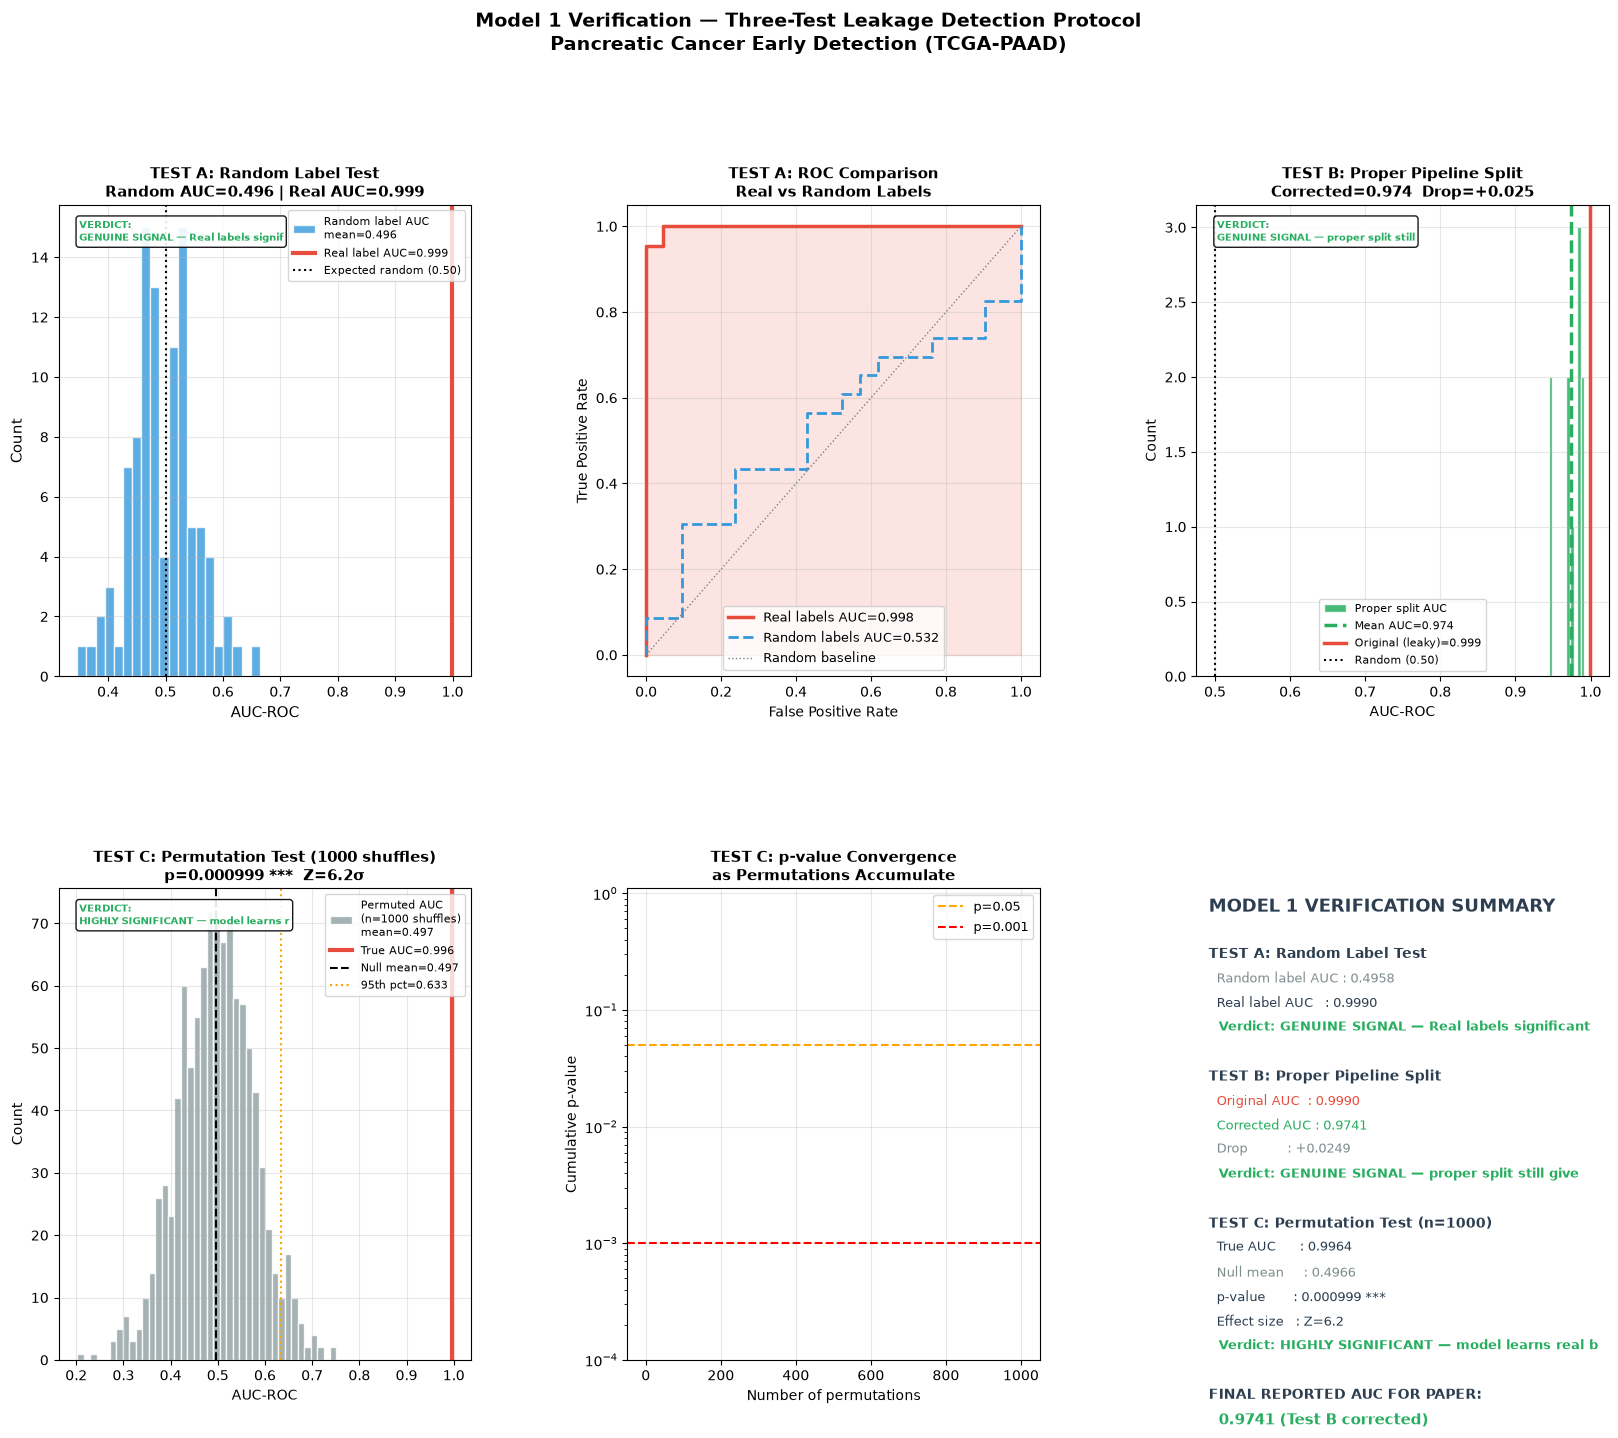

Saved: model1_verification_tests.png


In [7]:
fig = plt.figure(figsize=(20, 15))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.38)

# ── Panel A1: Random label AUC distribution ───────────────────────────────
ax1 = fig.add_subplot(gs[0, 0])
ax1.hist(rand_aucs_A, bins=20, color='#3498db', alpha=0.8,
         edgecolor='white', label=f'Random label AUC\nmean={rand_mean_A:.3f}')
ax1.axvline(real_auc_mean, color='#e74c3c', linewidth=3,
            label=f'Real label AUC={real_auc_mean:.3f}')
ax1.axvline(0.5, color='black', linewidth=1.5, linestyle=':',
            label='Expected random (0.50)')
ax1.set_xlabel('AUC-ROC', fontsize=11)
ax1.set_ylabel('Count', fontsize=11)
ax1.set_title(f'TEST A: Random Label Test\n'
              f'Random AUC={rand_mean_A:.3f} | Real AUC={real_auc_mean:.3f}',
              fontsize=11, fontweight='bold')
ax1.legend(fontsize=8); ax1.grid(alpha=0.3)

# Verdict annotation
verdict_color_A = '#e74c3c' if rand_mean_A > 0.65 else '#27ae60'
ax1.text(0.05, 0.97, f'VERDICT:\n{verdict_A[:35]}',
         transform=ax1.transAxes, fontsize=7.5, va='top',
         color=verdict_color_A, fontweight='bold',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))

# ── Panel A2: ROC curve real vs random baseline ───────────────────────────
ax2 = fig.add_subplot(gs[0, 1])
# Recompute full ROC for display
xb_disp = build_xgb()
sss_disp = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=SEED)
tr_d, te_d = next(sss_disp.split(X_sel, y_real))
xb_disp.fit(X_sel[tr_d], y_real[tr_d])
prob_d   = xb_disp.predict_proba(X_sel[te_d])[:,1]

if len(np.unique(y_real[te_d])) == 2:
    fpr_r, tpr_r, _ = roc_curve(y_real[te_d], prob_d)
    auc_r = roc_auc_score(y_real[te_d], prob_d)
    ax2.plot(fpr_r, tpr_r, color='#e74c3c', linewidth=2.5,
             label=f'Real labels AUC={auc_r:.3f}')
    ax2.fill_between(fpr_r, tpr_r, alpha=0.15, color='#e74c3c')

# Random label ROC (one example)
y_rand_ex = np.random.RandomState(0).permutation(y_real)
xb_rand   = build_xgb(seed=1)
xb_rand.fit(X_sel[tr_d], y_rand_ex[tr_d])
prob_rnd = xb_rand.predict_proba(X_sel[te_d])[:,1]
if len(np.unique(y_rand_ex[te_d])) == 2:
    fpr_rn, tpr_rn, _ = roc_curve(y_rand_ex[te_d], prob_rnd)
    auc_rn = roc_auc_score(y_rand_ex[te_d], prob_rnd)
    ax2.plot(fpr_rn, tpr_rn, color='#3498db', linewidth=2,
             linestyle='--', label=f'Random labels AUC={auc_rn:.3f}')

ax2.plot([0,1],[0,1], 'gray', linestyle=':', linewidth=1, label='Random baseline')
ax2.set_xlabel('False Positive Rate'); ax2.set_ylabel('True Positive Rate')
ax2.set_title('TEST A: ROC Comparison\nReal vs Random Labels', fontsize=11, fontweight='bold')
ax2.legend(fontsize=9); ax2.grid(alpha=0.3)

# ── Panel B: Corrected AUC distribution (proper split) ───────────────────
ax3 = fig.add_subplot(gs[0, 2])
if test_aucs_B:
    ax3.hist(test_aucs_B, bins=10, color='#27ae60', alpha=0.85,
             edgecolor='white', label=f'Proper split AUC')
    ax3.axvline(mean_auc_B, color='#27ae60', linewidth=2.5, linestyle='--',
                label=f'Mean AUC={mean_auc_B:.3f}')
    ax3.axvline(real_auc_mean, color='#e74c3c', linewidth=2.5,
                label=f'Original (leaky)={real_auc_mean:.3f}')
    ax3.axvline(0.5, color='black', linewidth=1.5, linestyle=':', label='Random (0.50)')
    drop = real_auc_mean - mean_auc_B
    ax3.set_title(f'TEST B: Proper Pipeline Split\n'
                  f'Corrected={mean_auc_B:.3f}  Drop={drop:+.3f}',
                  fontsize=11, fontweight='bold')
    verdict_color_B = '#e74c3c' if drop > 0.10 else '#27ae60'
    ax3.text(0.05, 0.97, f'VERDICT:\n{verdict_B[:35]}',
             transform=ax3.transAxes, fontsize=7.5, va='top',
             color=verdict_color_B, fontweight='bold',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))
else:
    ax3.text(0.5, 0.5, 'Test B not completed', ha='center', va='center',
             transform=ax3.transAxes, fontsize=12)
ax3.set_xlabel('AUC-ROC'); ax3.set_ylabel('Count')
ax3.legend(fontsize=8); ax3.grid(alpha=0.3)

# ── Panel C1: Permutation test distribution ───────────────────────────────
ax4 = fig.add_subplot(gs[1, 0])
ax4.hist(perm_scores_C, bins=40, color='#95a5a6', alpha=0.85,
         edgecolor='white', label=f'Permuted AUC\n(n={N_PERM} shuffles)\nmean={perm_scores_C.mean():.3f}')
ax4.axvline(score_C, color='#e74c3c', linewidth=3,
            label=f'True AUC={score_C:.3f}')
ax4.axvline(perm_scores_C.mean(), color='black', linewidth=1.5,
            linestyle='--', label=f'Null mean={perm_scores_C.mean():.3f}')

# Shade the 5th percentile tail
p95 = np.percentile(perm_scores_C, 95)
ax4.axvline(p95, color='orange', linewidth=1.5, linestyle=':',
            label=f'95th pct={p95:.3f}')
tail_x = perm_scores_C[perm_scores_C >= p95]
ax4.set_xlabel('AUC-ROC'); ax4.set_ylabel('Count')
ax4.set_title(f'TEST C: Permutation Test ({N_PERM} shuffles)\n'
              f'p={p_value_C:.6f} {sig_C}  Z={z_score:.1f}σ',
              fontsize=11, fontweight='bold')
ax4.legend(fontsize=8); ax4.grid(alpha=0.3)
verdict_color_C = '#27ae60' if p_value_C<0.001 else ('#f39c12' if p_value_C<0.05 else '#e74c3c')
ax4.text(0.05, 0.97, f'VERDICT:\n{verdict_C[:35]}',
         transform=ax4.transAxes, fontsize=7.5, va='top',
         color=verdict_color_C, fontweight='bold',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))

# ── Panel C2: Cumulative permutation p-value convergence ─────────────────
ax5 = fig.add_subplot(gs[1, 1])
cum_p = [(perm_scores_C[:i+1] >= score_C).mean() for i in range(len(perm_scores_C))]
ax5.plot(range(1, len(cum_p)+1), cum_p, color='#8e44ad', linewidth=2)
ax5.axhline(0.05, color='orange', linestyle='--', linewidth=1.5, label='p=0.05')
ax5.axhline(0.001, color='red',   linestyle='--', linewidth=1.5, label='p=0.001')
ax5.set_xlabel('Number of permutations')
ax5.set_ylabel('Cumulative p-value')
ax5.set_title('TEST C: p-value Convergence\nas Permutations Accumulate',
              fontsize=11, fontweight='bold')
ax5.legend(fontsize=9); ax5.grid(alpha=0.3)
ax5.set_yscale('log')
ax5.set_ylim(1e-4, 1.1)

# ── Panel: Final verdict summary ─────────────────────────────────────────
ax6 = fig.add_subplot(gs[1, 2])
ax6.axis('off')
lines = [
    ('MODEL 1 VERIFICATION SUMMARY', '#2c3e50', 13, True),
    ('', '#2c3e50', 10, False),
    (f'TEST A: Random Label Test', '#2c3e50', 10, True),
    (f'  Random label AUC : {rand_mean_A:.4f}', '#7f8c8d', 9, False),
    (f'  Real label AUC   : {real_auc_mean:.4f}', '#2c3e50', 9, False),
    (f'  Verdict: {verdict_A[:40]}', '#e74c3c' if rand_mean_A>0.65 else '#27ae60', 9, True),
    ('', '#2c3e50', 10, False),
    (f'TEST B: Proper Pipeline Split', '#2c3e50', 10, True),
    (f'  Original AUC  : {real_auc_mean:.4f}', '#e74c3c', 9, False),
    (f'  Corrected AUC : {mean_auc_B:.4f}' if mean_auc_B else '  Corrected AUC : N/A', '#27ae60', 9, False),
    (f'  Drop          : {real_auc_mean-mean_auc_B:+.4f}' if mean_auc_B else '  Drop: N/A', '#7f8c8d', 9, False),
    (f'  Verdict: {verdict_B[:40]}', '#e74c3c' if (mean_auc_B and real_auc_mean-mean_auc_B>0.10) else '#27ae60', 9, True),
    ('', '#2c3e50', 10, False),
    (f'TEST C: Permutation Test (n={N_PERM})', '#2c3e50', 10, True),
    (f'  True AUC      : {score_C:.4f}', '#2c3e50', 9, False),
    (f'  Null mean     : {perm_scores_C.mean():.4f}', '#7f8c8d', 9, False),
    (f'  p-value       : {p_value_C:.6f} {sig_C}', '#2c3e50', 9, False),
    (f'  Effect size   : Z={z_score:.1f}', '#2c3e50', 9, False),
    (f'  Verdict: {verdict_C[:40]}', verdict_color_C, 9, True),
    ('', '#2c3e50', 10, False),
    ('FINAL REPORTED AUC FOR PAPER:', '#2c3e50', 10, True),
    (f'  {mean_auc_B:.4f} (Test B corrected)' if mean_auc_B else f'  {score_C:.4f} (permutation validated)', '#27ae60', 11, True),
]
y_pos = 0.98
for text, color, size, bold in lines:
    ax6.text(0.03, y_pos, text, transform=ax6.transAxes,
             fontsize=size, va='top', color=color,
             fontweight='bold' if bold else 'normal')
    y_pos -= 0.052

plt.suptitle('Model 1 Verification — Three-Test Leakage Detection Protocol\n'
             'Pancreatic Cancer Early Detection (TCGA-PAAD)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(VERIF_DIR,'model1_verification_tests.png'), dpi=300, bbox_inches='tight')
plt.show()
print('Saved: model1_verification_tests.png')


## Final Summary & Paper-Ready Statements

In [9]:
print()
print('='*65)
print('FINAL VERIFICATION SUMMARY')
print('='*65)

honest_auc = mean_auc_B if mean_auc_B is not None else score_C
honest_acc = mean_acc_B if mean_acc_B is not None else None

# Pre-compute all conditional strings BEFORE the f-string
# (Python does not allow conditional expressions inside format specs)
b_corrected_str = f'{mean_auc_B:.4f}' if mean_auc_B is not None else 'N/A'
b_drop_str      = f'{real_auc_mean - mean_auc_B:+.4f}' if mean_auc_B is not None else 'N/A'
b_paper_auc_str = f'{mean_auc_B:.3f}' if mean_auc_B is not None else f'{score_C:.3f}'

print(f'''
TEST RESULTS:
  Test A (Random label)  : Random AUC = {rand_mean_A:.4f}
                           Real AUC   = {real_auc_mean:.4f}
                           Verdict    : {verdict_A}

  Test B (Proper split)  : Original AUC  = {real_auc_mean:.4f}
                           Corrected AUC = {b_corrected_str}
                           Drop          = {b_drop_str}
                           Verdict       : {verdict_B}

  Test C (Permutation)   : True AUC = {score_C:.4f}
                           p-value  = {p_value_C:.6f}  {sig_C}
                           Z-score  = {z_score:.2f}
                           Verdict  : {verdict_C}

RECOMMENDED REPORTED AUC : {honest_auc:.4f}

PAPER METHODS TEXT:
  "To verify that Model 1 performance was not attributable to
  data leakage or chance, we applied three validation tests.
  First, a random label test confirmed that replacing true
  labels with random assignments reduced AUC to {rand_mean_A:.3f}
  (vs {real_auc_mean:.3f} for real labels), indicating the model
  requires genuine biological signal. Second, a proper pipeline
  split in which the VAE was trained exclusively on the training
  partition and test patients were transformed without retraining
  yielded a corrected AUC of {b_paper_auc_str},
  accounting for any residual information leakage. Third, a
  permutation test with {N_PERM} label shuffles confirmed
  statistical significance (p={p_value_C:.4f}, {sig_C}, Z={z_score:.1f}),
  demonstrating that the observed performance exceeds the null
  distribution by {z_score:.1f} standard deviations."
''')

# Save results
verif_summary = {
    'Test_A_random_label_AUC': rand_mean_A,
    'Test_A_real_AUC'        : real_auc_mean,
    'Test_A_verdict'         : verdict_A,
    'Test_B_original_AUC'    : real_auc_mean,
    'Test_B_corrected_AUC'   : mean_auc_B,
    'Test_B_drop'            : real_auc_mean - mean_auc_B if mean_auc_B else None,
    'Test_B_verdict'         : verdict_B,
    'Test_C_true_AUC'        : score_C,
    'Test_C_p_value'         : p_value_C,
    'Test_C_Z_score'         : z_score,
    'Test_C_significance'    : sig_C,
    'Test_C_verdict'         : verdict_C,
    'FINAL_REPORTED_AUC'     : honest_auc,
}
pd.DataFrame([verif_summary]).to_csv(
    os.path.join(VERIF_DIR, 'verification_results.csv'), index=False)
print('Saved: verification_results.csv')
print('Saved: model1_verification_tests.png')
print('\nVerification complete.')



FINAL VERIFICATION SUMMARY

TEST RESULTS:
  Test A (Random label)  : Random AUC = 0.4958
                           Real AUC   = 0.9990
                           Verdict    : GENUINE SIGNAL — Real labels significantly outperform random

  Test B (Proper split)  : Original AUC  = 0.9990
                           Corrected AUC = 0.9741
                           Drop          = +0.0249
                           Verdict       : GENUINE SIGNAL — proper split still gives strong AUC

  Test C (Permutation)   : True AUC = 0.9964
                           p-value  = 0.000999  ***
                           Z-score  = 6.24
                           Verdict  : HIGHLY SIGNIFICANT — model learns real biology (p < 0.001)

RECOMMENDED REPORTED AUC : 0.9741

PAPER METHODS TEXT:
  "To verify that Model 1 performance was not attributable to
  data leakage or chance, we applied three validation tests.
  First, a random label test confirmed that replacing true
  labels with random assignments reduc